# Load data

Initial notebook to load in datasets given a region.

I'll move functions etc. to the parks_report module once they are tested and working; these numbered notebooks are a record of this work-in-progress.

In [1]:
import json
from urllib.request import urlopen
import pandas as pd
from urllib.parse import quote
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Given a region code and a dataset name, load the dataset appropriately.

Layout:

For region E12000001:

- All data stored in https://github.com/Safer-Parks/E12000001
- List of authorities within region: https://raw.githubusercontent.com/Safer-Parks/E12000001/refs/heads/main/E12000001_lut.geojson
- For each authority code in the lut, there is a folder containing all the data: https://github.com/Safer-Parks/E12000001/tree/main/E06000001
- Park boundaries are provided in: https://raw.githubusercontent.com/Safer-Parks/E12000001/refs/heads/main/E06000001/Hartlepool_parks.geojson 

The park boundaries file are included in a geojson that contains these properties (example first entry):

```
{ "type": "Feature", "properties": { "Park Name": "Henry Smith's Terrace", "Type (OS)": "Public Park Or Garden", "Type (OSM)": null, "flag": "OS", "country": "England", "Total Area (m²)": 43830.917069367169, "region_id": "E12000001", "authority_id": "E06000001", "auth_name_e": "Hartlepool", "park_offical_id": "HARTL_2", "old_park_id": "HARTL_5bead368357a", "new_park_id": "07104eb794fa" }, "geometry": { "type": "Polygon", "coordinates": [ [ [ 452668.099999999802094, 534303.129999998142011 ], [ 452703.099999999743886, 534304.199999996926636 ], [ 452726.64999999984866, 534299.449999998323619 ], [ 452743.049999999813735, 534286.749999998486601 ], [ 452877.499999999708962, 534212.549999998533167 ], [ 452907.949999999837019, 534188.349999998812564 ], [ 452920.599999999802094, 534181.149999996181577 ], [ 452924.349999999743886, 534182.96999999997206 ], [ 453040.849999999802094, 534115.049999999348074 ], [ 453066.749999999883585, 534090.049999998882413 ], [ 453098.779999999853317, 534048.109999997657724 ], [ 453082.54999999969732, 534033.699999998789281 ], [ 453080.89999999984866, 534022.249999997438863 ], [ 453124.859999999811407, 533957.699999997159466 ], [ 453130.799999999755528, 533961.699999997043051 ], [ 453143.199999999837019, 533932.499999998486601 ], [ 453135.279999999795109, 533926.389999998034909 ], [ 453134.149999999906868, 533925.499999999650754 ], [ 453097.209999999846332, 533960.57999999972526 ], [ 453088.849999999860302, 533950.149999997927807 ], [ 453070.599999999802094, 533946.469999998109415 ], [ 453069.669999999809079, 533950.54999999795109 ], [ 452986.499999999767169, 533933.989999998593703 ], [ 452974.599999999802094, 533990.849999999278225 ], [ 452921.6799999998766, 533980.749999997555278 ], [ 452921.009999999892898, 533983.609999999520369 ], [ 452893.499999999825377, 534081.399999998160638 ], [ 452854.749999999767169, 534159.489999996731058 ], [ 452829.949999999720603, 534199.899999997927807 ], [ 452802.949999999895226, 534228.949999997392297 ], [ 452766.549999999813735, 534253.899999997927807 ], [ 452718.099999999976717, 534274.839999997173436 ], [ 452700.349999999743886, 534281.669999998412095 ], [ 452664.189999999827705, 534302.099999997182749 ], [ 452668.099999999802094, 534303.129999998142011 ] ] ] } },
```

In [2]:
regions = [
    "E12000001",
    "E12000002",
    "E12000003",
    "E12000004",
    "E12000005",
    "E12000006",
    "E12000007",
    "E12000008",
    "E12000009",
    "W10000001",
    "W10000006",
    "W10000007",
    "W10000008",
    "W10000009",
    ]

In [3]:
def list_authorities(region_code):
    if region_code not in regions:
        raise ValueError(f"Unknown region code: {region_code}")

    url = (
        f"https://raw.githubusercontent.com/Safer-Parks/"
        f"{region_code}/refs/heads/main/{region_code}_lut.geojson"
    )

    with urlopen(url) as response:
        lut = json.load(response)

    authorities = [
        {
            "region_code": feature["properties"]["region_id"],
            "region_name": feature["properties"]["reg_name_e"],
            "authority_code": feature["properties"]["authority_id"],
            "authority_name": feature["properties"]["auth_name_e"],
        }
        for feature in lut["features"]
    ]
    authorities.sort(key=lambda row: row["authority_name"])

    for row in authorities:
        print(
            f"{row['region_code']} ({row['region_name']}) | "
            f"{row['authority_code']} | {row['authority_name']}"
        )

    return authorities


In [4]:
authorities = list_authorities(regions[2])

E12000003 (Yorkshire and The Humber) | E08000016 | Barnsley
E12000003 (Yorkshire and The Humber) | E08000032 | Bradford
E12000003 (Yorkshire and The Humber) | E08000033 | Calderdale
E12000003 (Yorkshire and The Humber) | E08000017 | Doncaster
E12000003 (Yorkshire and The Humber) | E06000011 | East Riding of Yorkshire
E12000003 (Yorkshire and The Humber) | E06000010 | Kingston upon Hull, City of
E12000003 (Yorkshire and The Humber) | E08000034 | Kirklees
E12000003 (Yorkshire and The Humber) | E08000035 | Leeds
E12000003 (Yorkshire and The Humber) | E06000012 | North East Lincolnshire
E12000003 (Yorkshire and The Humber) | E06000013 | North Lincolnshire
E12000003 (Yorkshire and The Humber) | E06000065 | North Yorkshire
E12000003 (Yorkshire and The Humber) | E08000018 | Rotherham
E12000003 (Yorkshire and The Humber) | E08000019 | Sheffield
E12000003 (Yorkshire and The Humber) | E08000036 | Wakefield
E12000003 (Yorkshire and The Humber) | E06000014 | York


As well as printing out a summary, also saves as a dictionary then for further querying:

In [5]:
authorities

[{'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E08000016',
  'authority_name': 'Barnsley'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E08000032',
  'authority_name': 'Bradford'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E08000033',
  'authority_name': 'Calderdale'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E08000017',
  'authority_name': 'Doncaster'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E06000011',
  'authority_name': 'East Riding of Yorkshire'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E06000010',
  'authority_name': 'Kingston upon Hull, City of'},
 {'region_code': 'E12000003',
  'region_name': 'Yorkshire and The Humber',
  'authority_code': 'E08000034',
  'autho

## Per-authority basic stats

For each authority in this dictionary:

- Function that reads the park boundaries geojson (see first MD cell describing this)
- Pulls out area (already calculated, `Total Area (m^2)`)
- Pulls out type, either from OSM or OS: disregards anything labelled null; "Type (OS)" takes precedence if both do exist, maybe we just concatenate the secondary type to this (with a comma and space) if Type (OSM) also exists and is different.
- Saves this all to a mega-dataframe, so that we can get authority-level stats as well as region-level

In [6]:
def clean_type(value):
    """Treat missing, empty, and literal 'null' values as missing."""
    if value is None:
        return None

    value = value.strip()
    if not value or value.casefold() == "null":
        return None

    return value


def combine_types(type_os, type_osm):
    """Put OS first, adding OSM only when it is different."""
    type_os = clean_type(type_os)
    type_osm = clean_type(type_osm)

    if type_os and type_osm:
        if type_os.casefold() == type_osm.casefold():
            return type_os
        return f"{type_os}, {type_osm}"

    return type_os or type_osm


def load_authority_parks(authority):
    region_code = authority["region_code"]
    authority_code = authority["authority_code"]
    authority_name = authority["authority_name"]

    filename = quote(f"{authority_name}_parks.geojson", safe="")
    url = (
        f"https://raw.githubusercontent.com/Safer-Parks/"
        f"{region_code}/refs/heads/main/{authority_code}/{filename}"
    )

    with urlopen(url, timeout=60) as response:
        geojson = json.load(response)

    records = []
    for feature in geojson["features"]:
        props = feature["properties"]
        type_os = clean_type(props.get("Type (OS)"))
        type_osm = clean_type(props.get("Type (OSM)"))

        records.append({
            **authority,
            "park_id": props.get("new_park_id"),
            "park_name": props.get("Park Name"),
            "area_m2": props["Total Area (m²)"],
            "type_os": type_os,
            "type_osm": type_osm,
            "park_type": combine_types(type_os, type_osm),
        })

    print(f"{authority_name}: loaded {len(records)} parks")
    return records

In [7]:
columns = [
    "region_code", "region_name",
    "authority_code", "authority_name",
    "park_id", "park_name", "area_m2",
    "type_os", "type_osm", "park_type",
]

park_records = []
for authority in authorities:
    park_records.extend(load_authority_parks(authority))

parks = pd.DataFrame.from_records(park_records, columns=columns)
parks["area_m2"] = pd.to_numeric(parks["area_m2"], errors="raise")

print(f"Total parks: {len(parks)}")
print(f"Missing areas: {parks['area_m2'].isna().sum()}")
print(f"Missing types: {parks['park_type'].isna().sum()}")

parks.head()

Barnsley: loaded 135 parks
Bradford: loaded 152 parks
Calderdale: loaded 58 parks
Doncaster: loaded 149 parks
East Riding of Yorkshire: loaded 150 parks
Kingston upon Hull, City of: loaded 79 parks
Kirklees: loaded 176 parks
Leeds: loaded 346 parks
North East Lincolnshire: loaded 39 parks
North Lincolnshire: loaded 121 parks
North Yorkshire: loaded 339 parks
Rotherham: loaded 118 parks
Sheffield: loaded 200 parks
Wakefield: loaded 158 parks
York: loaded 71 parks
Total parks: 2291
Missing areas: 0
Missing types: 0


,region_code,region_name,authority_code,authority_name,park_id,park_name,area_m2,type_os,type_osm,park_type
0,E12000003,Yorkshire and The Humber,E08000016,Barnsley,9e90b4e65e38,Oberon Crescent,82498.058928,NaN,park,park
1,E12000003,Yorkshire and The Humber,E08000016,Barnsley,8d891598e99f,Mount Pleasant,6836.382045,Public Park Or Garden,NaN,Public Park Or Garden
2,E12000003,Yorkshire and The Humber,E08000016,Barnsley,24a260454024,Elland Close,142807.592669,Public Park Or Garden,NaN,Public Park Or Garden
3,E12000003,Yorkshire and The Humber,E08000016,Barnsley,0265cd5d9fc2,Brierey Close,7544.369106,Public Park Or Garden,NaN,Public Park Or Garden
4,E12000003,Yorkshire and The Humber,E08000016,Barnsley,7d905384e3b4,Royston Park,77443.689840,Public Park Or Garden,NaN,Public Park Or Garden


In [8]:
authority_stats = (
    parks.groupby(
        ["region_code", "region_name", "authority_code", "authority_name"],
        as_index=False,
    )
    .agg(
        park_count=("park_name", "size"),
        total_area_m2=("area_m2", lambda values: values.sum(min_count=1)),
        mean_area_m2=("area_m2", "mean"),
        median_area_m2=("area_m2", "median"),
        missing_area_count=("area_m2", lambda values: values.isna().sum()),
    )
)

region_stats = (
    parks.groupby(["region_code", "region_name"], as_index=False)
    .agg(
        park_count=("park_name", "size"),
        total_area_m2=("area_m2", lambda values: values.sum(min_count=1)),
        mean_area_m2=("area_m2", "mean"),
        median_area_m2=("area_m2", "median"),
        missing_area_count=("area_m2", lambda values: values.isna().sum()),
    )
)

authority_stats

,region_code,region_name,authority_code,authority_name,park_count,total_area_m2,mean_area_m2,median_area_m2,missing_area_count
0,E12000003,Yorkshire and The Humber,E06000010,"Kingston upon Hull, City of",79,3.737067e+06,47304.644939,22422.198315,0
1,E12000003,Yorkshire and The Humber,E06000011,East Riding of Yorkshire,150,1.024715e+07,68314.339205,14938.300585,0
2,E12000003,Yorkshire and The Humber,E06000012,North East Lincolnshire,39,2.195251e+06,56288.480318,26455.075560,0
3,E12000003,Yorkshire and The Humber,E06000013,North Lincolnshire,121,4.523070e+06,37380.741924,11871.981948,0
4,E12000003,Yorkshire and The Humber,E06000014,York,71,5.404851e+06,76124.664006,18111.672262,0
5,E12000003,Yorkshire and The Humber,E06000065,North Yorkshire,339,1.925480e+07,56798.812556,13549.821457,0
6,E12000003,Yorkshire and The Humber,E08000016,Barnsley,135,1.530021e+07,113334.921735,18552.314920,0
7,E12000003,Yorkshire and The Humber,E08000017,Doncaster,149,1.216386e+07,81636.653777,16059.926012,0
8,E12000003,Yorkshire and The Humber,E08000018,Rotherham,118,1.185411e+07,100458.561079,23578.527138,0
9,E12000003,Yorkshire and The Humber,E08000019,Sheffield,200,1.615909e+07,80795.435645,21312.392789,0


In [9]:
parks["park_type"] = (
    parks["park_type"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

In [10]:
type_counts = (
    parks.groupby(
        ["region_name", "authority_name", "park_type"],
        dropna=False,
    )
    .size()
    .reset_index(name="park_count")
)

type_counts

,region_name,authority_name,park_type,park_count
0,Yorkshire and The Humber,Barnsley,Dog Park,1
1,Yorkshire and The Humber,Barnsley,Garden,19
2,Yorkshire and The Humber,Barnsley,Park,65
3,Yorkshire and The Humber,Barnsley,"Park, Recreation Ground",1
4,Yorkshire and The Humber,Barnsley,Public Park Or Garden,49
...,...,...,...,...
69,Yorkshire and The Humber,York,Garden,11
70,Yorkshire and The Humber,York,"Meadow, Park",1
71,Yorkshire and The Humber,York,Park,29
72,Yorkshire and The Humber,York,"Park, Village Green",1


## Plotting results

Adding some basic plots per-region

In [11]:
region_code = regions[2] # Testing Yorkshire

region_parks = parks.loc[parks["region_code"] == region_code].copy()
if region_parks.empty:
    raise ValueError(f"No parks loaded for region {region_code}")

region_name = region_parks["region_name"].iloc[0]
region_parks["area_ha"] = region_parks["area_m2"] / 10_000

# Logarithmic plots need positive, finite areas.
valid_area = np.isfinite(region_parks["area_ha"]) & (region_parks["area_ha"] > 0)
size_parks = region_parks.loc[valid_area].copy()

print(f"{region_name}: {len(region_parks)} parks")
print(f"Excluded from size plots (missing, non-finite or non-positive area): {(~valid_area).sum()}")

if size_parks.empty:
    raise ValueError("No positive, finite park areas available to plot")

sns.set_theme(style="whitegrid")

Yorkshire and The Humber: 2291 parks
Excluded from size plots (missing, non-finite or non-positive area): 0


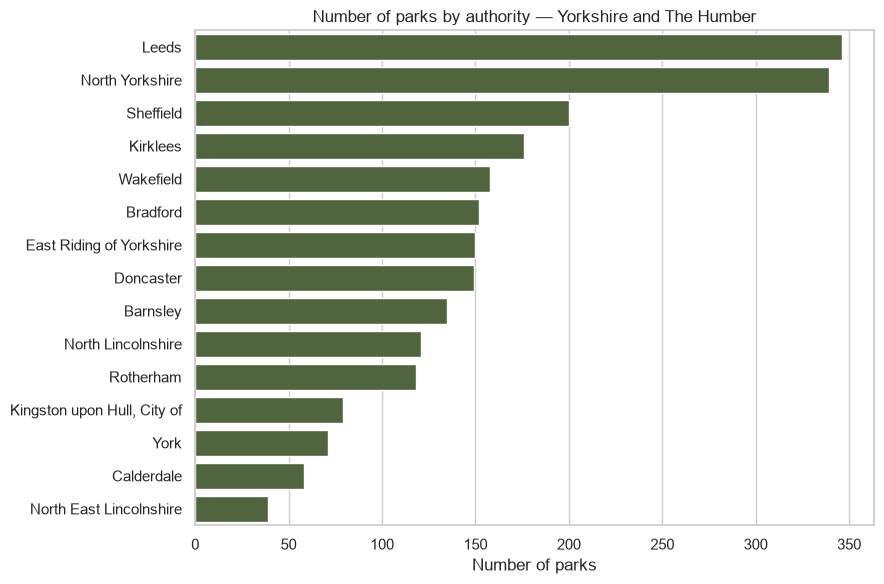

In [12]:
counts = (
    region_parks.groupby("authority_name")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, max(4, len(counts) * 0.4)))
sns.barplot(x=counts.values, y=counts.index, color="#4F6C37")
plt.title(f"Number of parks by authority — {region_name}")
plt.xlabel("Number of parks")
plt.ylabel("")
plt.tight_layout()
plt.show()

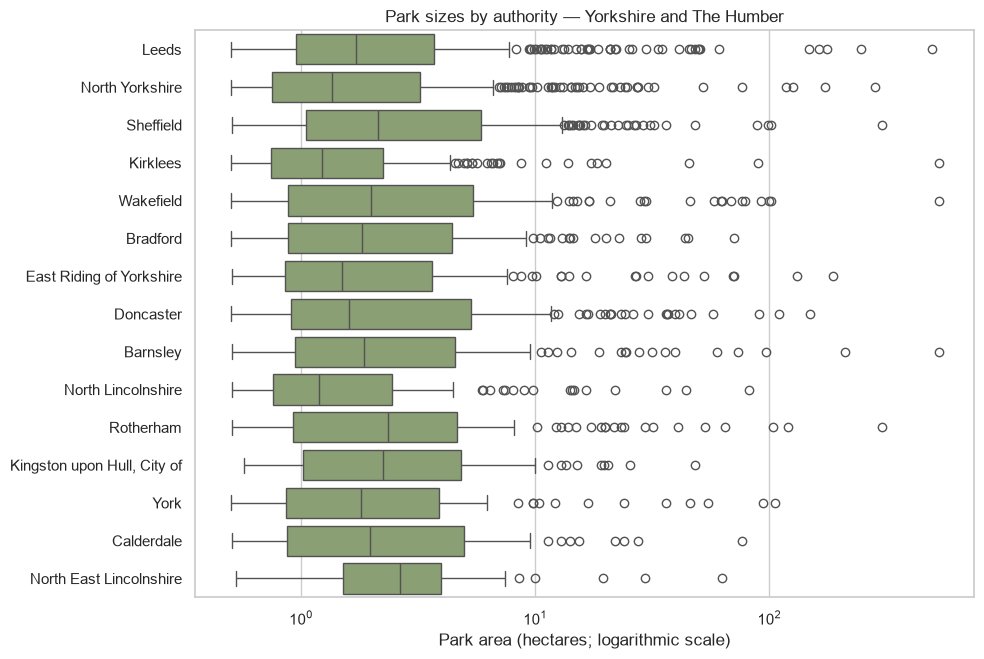

In [13]:
authority_order = counts.index.tolist()

plt.figure(figsize=(10, max(4, len(counts) * 0.45)))
sns.boxplot(
    data=size_parks,
    x="area_ha",
    y="authority_name",
    order=authority_order,
    color="#8BA66D",
)
plt.xscale("log")
plt.title(f"Park sizes by authority — {region_name}")
plt.xlabel("Park area (hectares; logarithmic scale)")
plt.ylabel("")
plt.tight_layout()
plt.show()

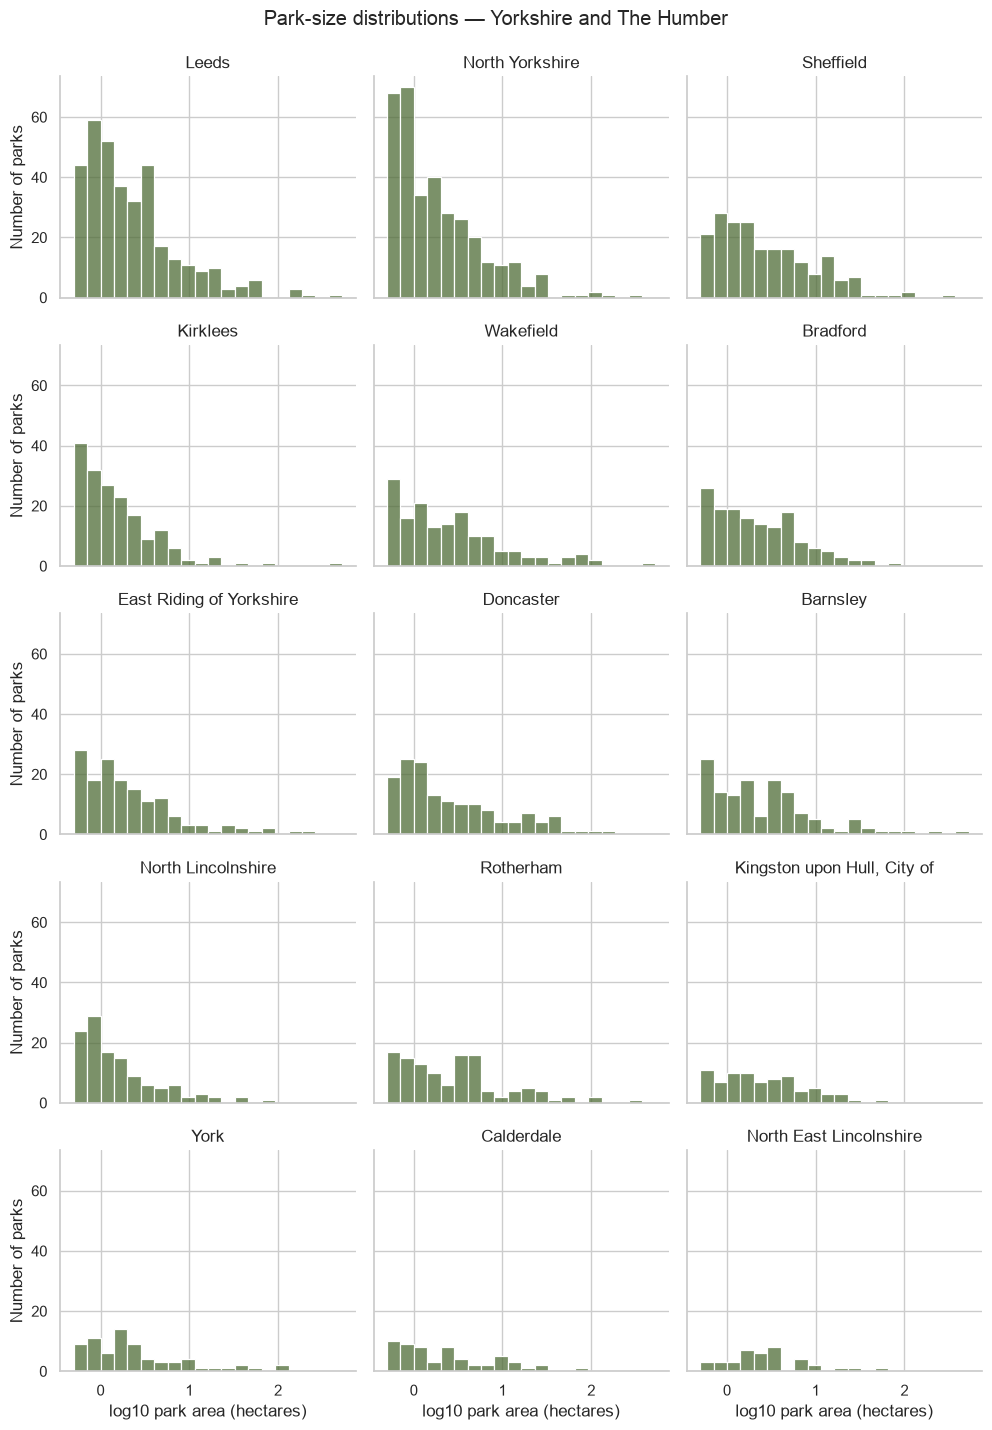

In [14]:
size_parks["log10_area_ha"] = np.log10(size_parks["area_ha"])

g = sns.displot(
    data=size_parks,
    x="log10_area_ha",
    col="authority_name",
    col_order=authority_order,
    col_wrap=3,
    bins=20,
    height=2.8,
    aspect=1.2,
    color="#4F6C37",
)

g.set_axis_labels("log10 park area (hectares)", "Number of parks")
g.set_titles("{col_name}")
g.figure.suptitle(f"Park-size distributions — {region_name}", y=1.02)
plt.show()